# Разговорные рекомендации музыки по пользовательскому намерению

**Тестовое задание для Инженерной школы НИУ ВШЭ × VK**

## Аннотация

В работе исследуется возможность рекомендовать музыкальные композиции
на основе естественно-языковых описаний пользовательских намерений:
настроения, ситуации прослушивания и желаемой атмосферы.

Сформирован каталог из **80 композиций**. Для **67 треков** с доступными
аудиопревью извлечены акустические характеристики и 512-мерные
аудиоэмбеддинги модели **CLAP**.

Рассмотрены три рекомендательных подхода:

1. Поиск по косинусному сходству текста и аудиоэмбеддингов CLAP.
2. CLAP с центрированием эмбеддингов.
3. Интерпретируемый baseline на основе жанра и оценённого BPM.

Качество оценено вручную по шкале от 0 до 3 на пяти исходных
пользовательских сценариях. Дополнительно исследована работа CLAP
на трёх новых, более конкретных запросах.

**Основной результат:** на пяти заранее заданных сценариях
baseline по жанру и BPM получил среднюю релевантность@5 **2,80**,
а исходный CLAP — **2,44**. При этом CLAP поддерживает
произвольные текстовые описания без создания отдельных правил
для каждого запроса.

Результаты носят характер пилотного исследования:
использован небольшой каталог и оценки одного человека.


## 1. Постановка задачи

### Цель

Исследовать, какие характеристики музыкальных композиций полезны
для рекомендаций по пользовательскому намерению, и реализовать
прототип системы поиска музыки по текстовому описанию.

### Исследовательские вопросы

- Можно ли использовать аудиоэмбеддинги для сопоставления
  музыкальных композиций с текстовыми запросами?
- Как качество CLAP соотносится с простым алгоритмом,
  использующим жанр и темп?
- Улучшает ли центрирование эмбеддингов качество рекомендаций?
- Насколько CLAP справляется с новыми, более сложными запросами?
- Какие ограничения имеют автоматические музыкальные признаки?

### Подход

Используются сохранённые аудиоэмбеддинги и извлечённые признаки.
Это позволяет воспроизводить анализ без повторной загрузки
и обработки всех аудиофрагментов.


## 2. Данные и происхождение каталога

Каталог включает 80 композиций:

- 40 треков из русскоязычного чарта;
- 40 международных композиций, подобранных для расширения
  жанрового и музыкального разнообразия.

Для 67 композиций доступны аудиопревью, которые использованы
для извлечения признаков. Остальные 13 композиций остаются
в каталоге метаданных, но не участвуют в аудиорекомендациях.

Подробная информация об источниках содержится в файлах
`DATASET_README.md` и `metadata_provenance.csv`.

**Ограничение:** выборка не является репрезентативной для всей
музыкальной индустрии. Доступность аудиопревью также может
вносить смещение в состав анализируемых треков.


## 3. Загрузка данных и проверка качества

*В этом разделе будут размещены исполняемые ячейки
для подключения Google Drive, загрузки данных и проверок.*


In [ ]:
# FINAL_NOTEBOOK_DATA_LOADING

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Подключаем Google Drive, если ноутбук открыт в Colab
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Google Colab не обнаружен. Используется локальная папка.")

project_dir = Path(
    "/content/drive/MyDrive/VK_Music_Recommendations"
)

assert project_dir.exists(), (
    f"Папка проекта не найдена: {project_dir}"
)

# Основные таблицы
dataset = pd.read_csv(
    project_dir / "music_dataset_final_candidate.csv"
)

features = pd.read_csv(
    project_dir / "music_semantic_features_v1.csv"
)

tempo_df = pd.read_csv(
    project_dir / "audio_tempo_features.csv"
)

energy_df = pd.read_csv(
    project_dir / "audio_energy_features.csv"
)

# Сохранённые аудиоэмбеддинги CLAP
with np.load(
    project_dir / "clap_audio_embeddings.npz"
) as embedding_file:
    song_ids = embedding_file["song_ids"].astype(str)
    audio_embeddings = embedding_file["embeddings"].copy()

# Единый тип идентификаторов
for table in [dataset, features, tempo_df, energy_df]:
    table["song_id"] = table["song_id"].astype(str)

# Проверки целостности
assert len(dataset) == 80, (
    "Неожиданное количество треков в каталоге"
)

assert len(song_ids) == len(audio_embeddings), (
    "Количество ID не совпадает с количеством эмбеддингов"
)

assert audio_embeddings.shape[1] == 512, (
    "Неожиданная размерность CLAP-эмбеддингов"
)

assert len(set(song_ids)) == len(song_ids), (
    "Обнаружены повторяющиеся ID аудиоэмбеддингов"
)

assert set(song_ids).issubset(set(dataset["song_id"])), (
    "Некоторые аудиоэмбеддинги не найдены в каталоге"
)

assert dataset["song_id"].is_unique, (
    "В каталоге есть повторяющиеся song_id"
)

# Сводка
data_summary = pd.DataFrame({
    "Показатель": [
        "Композиции в каталоге",
        "Композиции с аудиоэмбеддингами",
        "Композиции без аудиоэмбеддингов",
        "Размерность аудиоэмбеддинга",
        "Записи с оценкой BPM",
        "Записи с энергетическими признаками"
    ],
    "Значение": [
        len(dataset),
        len(song_ids),
        len(dataset) - len(song_ids),
        audio_embeddings.shape[1],
        len(tempo_df),
        len(energy_df)
    ]
})

print("=== СВОДКА ПО ДАННЫМ ===")
display(data_summary)

print("\n=== ПРИМЕРЫ КОМПОЗИЦИЙ ===")
display(
    dataset[
        ["artist", "title", "genre_group", "selection_group"]
    ].head(10)
)

print("\n=== ПРОПУСКИ В ОСНОВНЫХ ПОЛЯХ ===")
display(
    dataset[
        ["artist", "title", "genre_group",
         "release_year", "preview_url"]
    ].isna().sum().to_frame("Пропусков")
)

print("\n✅ Данные загружены, проверки пройдены.")


Mounted at /content/drive
=== СВОДКА ПО ДАННЫМ ===


,Показатель,Значение
0,Композиции в каталоге,80
1,Композиции с аудиоэмбеддингами,67
2,Композиции без аудиоэмбеддингов,13
3,Размерность аудиоэмбеддинга,512
4,Записи с оценкой BPM,67
5,Записи с энергетическими признаками,67



=== ПРИМЕРЫ КОМПОЗИЦИЙ ===


,artist,title,genre_group,selection_group
0,"madk1d, VILLIAN",ДИНАСТИЯ,Unknown,russian_chart
1,"Дора, Toxi$",ЗНАК,Hip-Hop/Rap,russian_chart
2,"Koss, ПЛУТТО",Земляк,Pop,russian_chart
3,Kai Angel,andy warhol,Unknown,russian_chart
4,"By Индия, MOT, Xcho",Шадэ,Pop,russian_chart
5,"урал гайсин, снялцепи",ты в моих мыслях навсегда,Hip-Hop/Rap,russian_chart
6,MIA BOYKA,ЭКСПОНАТ,Pop,russian_chart
7,ENZRO,Ты не бойся ночи,Pop,russian_chart
8,"Милана Некрасова, ЦУЕФА, LIZOGUB, Давид Туров,...",Я ТЕБЯ МОГНУ,Pop,russian_chart
9,Voskresenskii,Франсе,Unknown,russian_chart



=== ПРОПУСКИ В ОСНОВНЫХ ПОЛЯХ ===


,Пропусков
artist,0
title,0
genre_group,0
release_year,12
preview_url,13



✅ Данные загружены, проверки пройдены.


## 4. Музыкальные признаки

*Анализ жанров, BPM, акустической энергии
и семантических характеристик.*


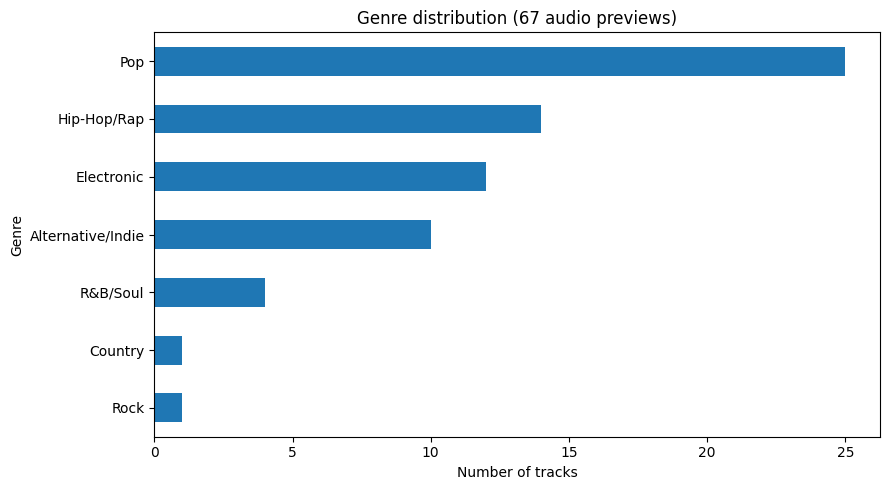

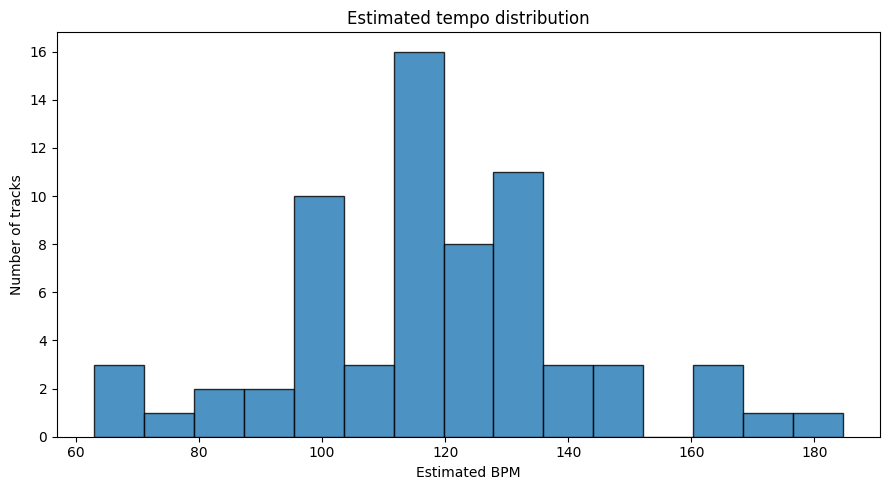

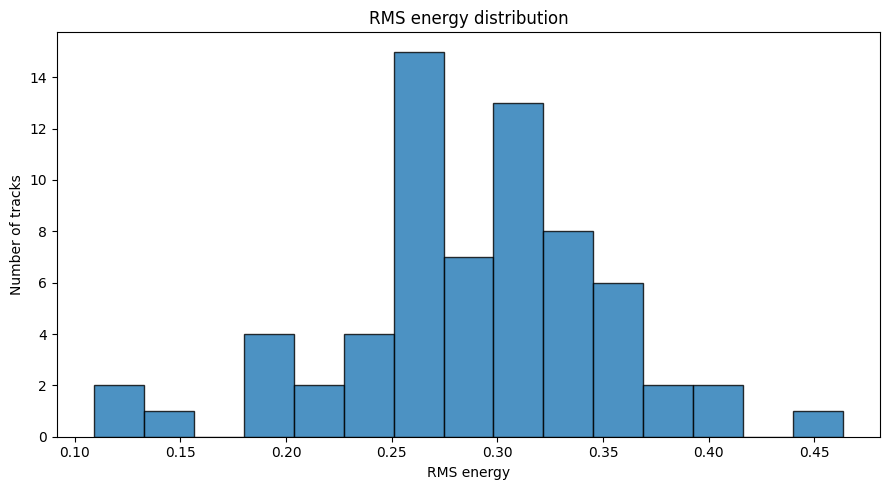

=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===


,tempo_bpm,rms_mean
count,67.000,67.000
mean,118.188,0.288
std,23.696,0.064
min,63.020,0.109
25%,103.360,0.258
50%,117.450,0.292
75%,129.200,0.325
max,184.570,0.463



=== ЖАНРЫ ===


,genre,tracks
0,Pop,25
1,Hip-Hop/Rap,14
2,Electronic,12
3,Alternative/Indie,10
4,R&B/Soul,4
5,Country,1
6,Rock,1


In [ ]:
# FINAL_NOTEBOOK_AUDIO_FEATURES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Сопоставляем признаки по song_id
audio_features = (
    features[["song_id", "genre_group"]]
    .merge(
        tempo_df[["song_id", "tempo_bpm"]],
        on="song_id",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        energy_df[["song_id", "rms_mean"]],
        on="song_id",
        how="inner",
        validate="one_to_one"
    )
)

assert len(audio_features) == 67, (
    "Ожидалось 67 композиций с аудиопризнаками"
)

audio_features["genre_group"] = (
    audio_features["genre_group"].fillna("Unknown")
)

# 1. Распределение жанров
genre_counts = (
    audio_features["genre_group"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(9, 5))
genre_counts.plot(kind="barh")
plt.title("Genre distribution (67 audio previews)")
plt.xlabel("Number of tracks")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

# 2. Распределение оценённого BPM
plt.figure(figsize=(9, 5))
plt.hist(
    audio_features["tempo_bpm"].dropna(),
    bins=15,
    edgecolor="black",
    alpha=0.8
)
plt.title("Estimated tempo distribution")
plt.xlabel("Estimated BPM")
plt.ylabel("Number of tracks")
plt.tight_layout()
plt.show()

# 3. Распределение акустической энергии
plt.figure(figsize=(9, 5))
plt.hist(
    audio_features["rms_mean"].dropna(),
    bins=15,
    edgecolor="black",
    alpha=0.8
)
plt.title("RMS energy distribution")
plt.xlabel("RMS energy")
plt.ylabel("Number of tracks")
plt.tight_layout()
plt.show()

print("=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===")
display(
    audio_features[
        ["tempo_bpm", "rms_mean"]
    ].describe().round(3)
)

print("\n=== ЖАНРЫ ===")
display(
    genre_counts.sort_values(ascending=False)
    .rename_axis("genre")
    .reset_index(name="tracks")
)


In [ ]:

print("=== СТОЛБЦЫ ТАБЛИЦЫ ЭНЕРГИИ ===")
print(energy_df.columns.tolist())

print("\n=== ПЕРВЫЕ ТРИ СТРОКИ ===")
display(energy_df.head(3))

print("\n=== СТОЛБЦЫ ТАБЛИЦЫ ТЕМПА ===")
print(tempo_df.columns.tolist())


=== СТОЛБЦЫ ТАБЛИЦЫ ЭНЕРГИИ ===
['song_id', 'rms_mean', 'rms_std', 'onset_mean', 'onset_std', 'energy_status']

=== ПЕРВЫЕ ТРИ СТРОКИ ===


,song_id,rms_mean,rms_std,onset_mean,onset_std,energy_status
0,2,0.342937,0.081111,1.319472,1.295568,ok
1,3,0.308826,0.111462,1.699628,1.553932,ok
2,5,0.277299,0.128814,1.779313,2.137944,ok



=== СТОЛБЦЫ ТАБЛИЦЫ ТЕМПА ===
['song_id', 'tempo_bpm', 'beat_regularity_cv', 'audio_duration_sec', 'tempo_status']


### Интерпретация музыкальных признаков

**Жанр.** Распределение жанров неравномерно, поэтому результаты
исследования могут сильнее отражать свойства наиболее
представленных категорий.

**Темп (BPM).** Значения получены автоматическим анализом
коротких аудиофрагментов. Оценка темпа может быть неточной,
в частности из-за неоднозначности половинного и двойного темпа.

**Акустическая энергия (RMS).** RMS характеризует средний уровень
амплитуды аудиосигнала, но не является прямой мерой субъективной
энергичности или эмоциональной интенсивности музыки.
На него также влияет нормализация аудио.

**Ограничение.** Аудиопризнаки рассчитаны только для 67 композиций
с доступными превью, а не для всех 80 треков каталога.


## 5. Аудиоэмбеддинги CLAP

*Описание модели, загрузка эмбеддингов
и анализ семантического сходства.*


### Как получены эмбеддинги

Для анализа музыкального содержания использована предобученная
модель **LAION-CLAP (`laion/clap-htsat-unfused`)**.

CLAP отображает аудио и текст в общее векторное пространство,
позволяя сравнивать музыкальные фрагменты с текстовыми описаниями
по косинусному сходству.

**Процедура подготовки:**

1. Для 67 композиций получены доступные короткие аудиопревью.
2. Аудио приведено к частоте дискретизации 48 кГц.
3. С помощью аудиоэнкодера CLAP извлечены векторы размерности 512.
4. Векторы нормализованы по L2-норме и сохранены в NPZ-файл.

Сохранение эмбеддингов позволяет воспроизводить последующий
анализ без повторного скачивания аудиофайлов и запуска
ресурсоёмкого аудиоэнкодера.

**Ограничение:** эмбеддинги описывают только доступные
фрагменты треков, а не обязательно композиции целиком.


=== АУДИОЭМБЕДДИНГИ CLAP ===
Количество треков: 67
Размерность векторов: 512
Диапазон L2-норм: 1.0 — 1.0
Среднее попарное сходство: 0.7346


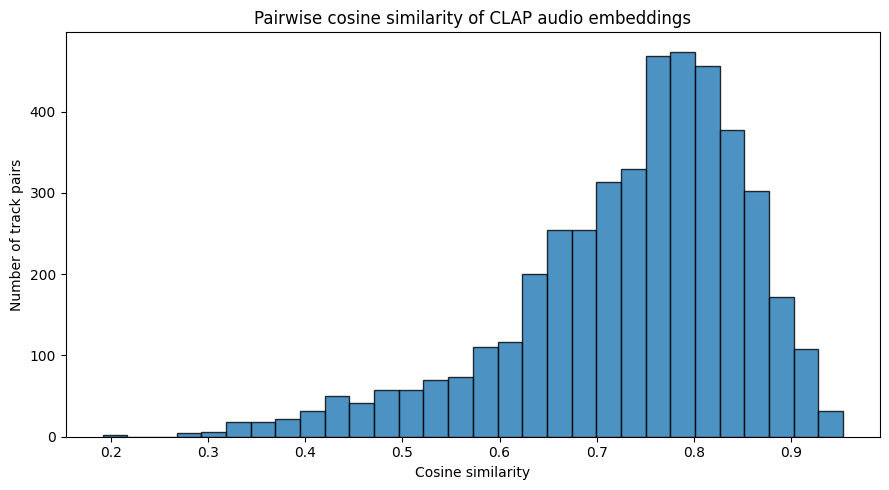


=== ПРИМЕР БЛИЗКИХ ТРЕКОВ ===
Исходный трек: Дора, Toxi$ — ЗНАК


,artist,title,cosine_similarity
0,Dua Lipa,Illusion,0.949
1,Dua Lipa,Training Season,0.909
2,Sabrina Carpenter,House Tour,0.900
3,SZA,My Turn,0.897
4,Kendrick Lamar,luther,0.893


In [ ]:
# FINAL_NOTEBOOK_CLAP_EMBEDDINGS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Проверяем структуру сохранённых эмбеддингов
embedding_norms = np.linalg.norm(
    audio_embeddings, axis=1
)

assert audio_embeddings.shape == (67, 512)
assert np.isfinite(audio_embeddings).all()
assert np.all(embedding_norms > 0)

print("=== АУДИОЭМБЕДДИНГИ CLAP ===")
print("Количество треков:", len(song_ids))
print("Размерность векторов:", audio_embeddings.shape[1])
print(
    "Диапазон L2-норм:",
    round(float(embedding_norms.min()), 4),
    "—",
    round(float(embedding_norms.max()), 4)
)

# Нормализуем для корректного косинусного сходства
normalized_audio_embeddings = (
    audio_embeddings / embedding_norms[:, None]
)

# Матрица попарного косинусного сходства
similarity_matrix = (
    normalized_audio_embeddings
    @ normalized_audio_embeddings.T
)

# Исключаем диагональ (сходство трека с самим собой)
off_diagonal = similarity_matrix[
    ~np.eye(len(song_ids), dtype=bool)
]

print(
    "Среднее попарное сходство:",
    round(float(off_diagonal.mean()), 4)
)

plt.figure(figsize=(9, 5))
plt.hist(
    off_diagonal,
    bins=30,
    edgecolor="black",
    alpha=0.8
)
plt.title("Pairwise cosine similarity of CLAP audio embeddings")
plt.xlabel("Cosine similarity")
plt.ylabel("Number of track pairs")
plt.tight_layout()
plt.show()

# Демонстрация близких композиций
example_index = 0
nearest_indices = np.argsort(
    similarity_matrix[example_index]
)[::-1]

nearest_indices = [
    i for i in nearest_indices
    if i != example_index
][:5]

song_lookup = (
    dataset.set_index("song_id")[["artist", "title"]]
)

rows = []

for i in nearest_indices:
    song_id = str(song_ids[i])
    rows.append({
        "artist": song_lookup.loc[song_id, "artist"],
        "title": song_lookup.loc[song_id, "title"],
        "cosine_similarity": float(
            similarity_matrix[example_index, i]
        )
    })

print("\n=== ПРИМЕР БЛИЗКИХ ТРЕКОВ ===")
print(
    "Исходный трек:",
    song_lookup.loc[str(song_ids[example_index]), "artist"],
    "—",
    song_lookup.loc[str(song_ids[example_index]), "title"]
)

display(
    pd.DataFrame(rows).round(3)
)


### Интерпретация

Косинусное сходство показывает близость музыкальных
представлений, сформированных моделью CLAP.

Близкие векторы могут соответствовать сходным характеристикам
звучания, инструментовке, вокалу или музыкальному стилю.
Однако **высокое сходство не гарантирует одинакового настроения
или одинаковой пользовательской релевантности**.

Попарное сходство внутри каталога также не является прямой
метрикой качества рекомендаций: для оценки рекомендаций
необходимы пользовательские запросы и независимая оценка
предложенных композиций.


## 6. Рекомендательные алгоритмы

*CLAP, центрирование эмбеддингов и baseline по жанру и BPM.*


### Сравниваемые подходы

Для исследования были использованы три метода ранжирования
композиций по пользовательскому запросу.

**Метод A — CLAP cosine similarity.**
Текстовый запрос преобразуется в эмбеддинг CLAP.
Композиции ранжируются по косинусному сходству между
текстовым и аудиоэмбеддингами.

**Метод B — Centered CLAP.**
Из аудиоэмбеддингов вычитается средний вектор каталога,
после чего сходство рассчитывается в центрированном
пространстве. Это экспериментальный способ уменьшить
влияние общего направления векторов.

**Метод C — жанр + BPM.**
Интерпретируемый базовый алгоритм: 50% оценки составляет
соответствие жанра заданному сценарию, ещё 50% —
близость BPM к целевому темпу. Для пяти тестовых сценариев
правила были заданы вручную.

Метод C не является универсальным обработчиком произвольного
текста: ему необходимы заранее заданные правила для каждого
сценария.

### Тестовые пользовательские запросы

1. Вечерняя прогулка.
2. Тренировка.
3. Вечеринка.
4. Грустное настроение.
5. Спокойный отдых.

Для CLAP запросы были вручную сформулированы на английском
языке, поскольку в этом эксперименте не использовалась
отдельная система автоматического перевода.


In [ ]:
# FINAL_NOTEBOOK_RECOMMENDATION_METHODS

import pandas as pd
from IPython.display import display

comparison_path = (
    project_dir / "final_comparison_by_query.csv"
)
summary_path = (
    project_dir / "final_comparison_summary.csv"
)

comparison = pd.read_csv(comparison_path)
comparison_summary = pd.read_csv(summary_path)

print("=== СРАВНЕНИЕ ПО ЗАПРОСАМ ===")
display(comparison.round(3))

print("\n=== СВОДНОЕ СРАВНЕНИЕ ===")
display(comparison_summary.round(3))

print("\nПроверка: файлы результатов успешно загружены.")


=== СРАВНЕНИЕ ПО ЗАПРОСАМ ===


,query,method,mean_relevance_at_5,ndcg_at_5
0,Вечерняя прогулка,A,2.8,0.806
1,Вечерняя прогулка,B,2.6,0.709
2,Тренировка,A,2.6,0.684
3,Тренировка,B,2.4,0.648
4,Вечеринка,A,2.6,0.803
5,Вечеринка,B,2.2,0.551
6,Грустное настроение,A,1.8,0.426
7,Грустное настроение,B,1.2,0.431
8,Спокойный отдых,A,2.4,0.612
9,Спокойный отдых,B,2.4,0.623



=== СВОДНОЕ СРАВНЕНИЕ ===


,method,mean_relevance_at_5,ndcg_at_5
0,A,2.44,0.666
1,B,2.16,0.592
2,C,2.80,0.907



Проверка: файлы результатов успешно загружены.


In [ ]:

# Шаг 172. Проверяем файлы ручной оценки рекомендаций

import pandas as pd

evaluation_files = [
    "manual_relevance_evaluation.csv",
    "baseline_manual_relevance.csv",
    "recommendations_evaluated.csv",
    "recommendation_metrics_by_query.csv"
]

for filename in evaluation_files:
    print(f"\n{'=' * 55}")
    print("Файл:", filename)

    table = pd.read_csv(project_dir / filename)

    print("Размер:", table.shape)
    print("Столбцы:", table.columns.tolist())

    display(table.head(3))



Файл: manual_relevance_evaluation.csv
Размер: (37, 6)
Столбцы: ['evaluation_id', 'query', 'song_id', 'artist', 'title', 'relevance_0_3']


,evaluation_id,query,song_id,artist,title,relevance_0_3
0,1,Вечерняя прогулка,65,Bicep,Lemonder,2
1,2,Вечерняя прогулка,66,Overmono,After The Rain,3
2,3,Вечерняя прогулка,43,Sabrina Carpenter,Manchild,3



Файл: baseline_manual_relevance.csv
Размер: (22, 7)
Столбцы: ['query', 'rank', 'song_id', 'artist', 'title', 'relevance_0_3', 'evaluation_id']


,query,rank,song_id,artist,title,relevance_0_3,evaluation_id
0,Вечерняя прогулка,1,29,IOWA,МЫ,3,1
1,Вечерняя прогулка,2,63,Arctic Monkeys,I Bet You Look Good on the Dancefloor (Live),2,2
2,Вечерняя прогулка,4,44,Billie Eilish,BIRDS OF A FEATHER,3,3



Файл: recommendations_evaluated.csv
Размер: (50, 7)
Столбцы: ['query', 'method', 'rank', 'song_id', 'artist', 'title', 'relevance_0_3']


,query,method,rank,song_id,artist,title,relevance_0_3
0,Вечерняя прогулка,A,1,65,Bicep,Lemonder,2
1,Вечерняя прогулка,A,2,66,Overmono,After The Rain,3
2,Вечерняя прогулка,A,3,43,Sabrina Carpenter,Manchild,3



Файл: recommendation_metrics_by_query.csv
Размер: (10, 4)
Столбцы: ['query', 'method', 'mean_relevance_at_5', 'ndcg_at_5']


,query,method,mean_relevance_at_5,ndcg_at_5
0,Вечерняя прогулка,A,2.8,0.806194
1,Вечерняя прогулка,B,2.6,0.709291
2,Тренировка,A,2.6,0.683916


### Что именно сравнивается

Здесь приведены результаты ранее проведённого эксперимента.
Для каждого из пяти запросов были сформированы топ-5
рекомендаций каждого метода, после чего композиции оценены
вручную по шкале от 0 до 3.

Оценки поставлены одним слушателем. Одинаковая пара
«запрос — композиция» получала одну и ту же оценку
независимо от рекомендательного метода.

**Важно:** ручные правила жанра и BPM подбирались для этих
же пяти сценариев. Поэтому преимущество метода C в данном
эксперименте нельзя автоматически переносить на новые,
непредусмотренные запросы.


## 7. Оценка качества рекомендаций

*Ручная оценка, релевантность@5, NDCG@5
и сопоставление трёх подходов.*


### Протокол ручной оценки

Для каждого из пяти пользовательских сценариев
сформированы топ-5 рекомендаций методами A, B и C.

Один слушатель оценил релевантность композиций по шкале:

- **0** — не соответствует запросу;
- **1** — соответствует слабо;
- **2** — скорее соответствует;
- **3** — хорошо соответствует.

Одинаковая композиция в рамках одного запроса оценивалась
один раз, даже если встречалась в рекомендациях нескольких
алгоритмов.

Использованы две метрики:

**Mean Relevance@5** — среднее значение пяти оценок
релевантности.

**NDCG@5** — метрика, учитывающая не только релевантность,
но и порядок композиций в выдаче. Используется
экспоненциальная полезность `2^relevance - 1`.

Для сопоставимости нормирующий идеальный рейтинг
формируется из **общего пула оценённых кандидатов**
для каждого запроса, а не отдельно для каждого метода.
Этот пул не включает все 67 доступных треков,
поэтому NDCG характеризует сравнение внутри
сформированного экспериментального пула.


In [ ]:
# FINAL_NOTEBOOK_EVALUATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Рекомендации A и B с уже присвоенными оценками
ab = pd.read_csv(
    project_dir / "recommendations_evaluated.csv"
)

# Дополнительные оценки для метода C
baseline_ratings = pd.read_csv(
    project_dir / "baseline_manual_relevance.csv"
)

# Общий пул оценок: пара (запрос, трек) -> релевантность
all_ratings = pd.concat(
    [
        ab[["query", "song_id", "relevance_0_3"]],
        baseline_ratings[
            ["query", "song_id", "relevance_0_3"]
        ],
    ],
    ignore_index=True,
)

all_ratings["song_id"] = all_ratings["song_id"].astype(str)

# Проверяем, что повторные оценки одной пары согласованы
rating_consistency = (
    all_ratings.groupby(["query", "song_id"])[
        "relevance_0_3"
    ].nunique()
)

assert (rating_consistency == 1).all(), (
    "Для одной пары запрос–трек найдены разные оценки"
)

rating_lookup = (
    all_ratings.drop_duplicates(["query", "song_id"])
    .set_index(["query", "song_id"])["relevance_0_3"]
)

# Для A и B берём исходный порядок рекомендаций
ab_rankings = ab[
    ["query", "method", "rank", "song_id"]
].copy()

# Для C нужен полный исходный топ-5.
# Сначала ищем его в сохранённых файлах проекта.
candidate_files = [
    "baseline_recommendations.csv",
    "recommendations_baseline.csv",
    "baseline_top5.csv",
    "baseline_ranked_recommendations.csv",
]

baseline_rankings = None

for filename in candidate_files:
    path = project_dir / filename
    if path.exists():
        candidate = pd.read_csv(path)
        required = {"query", "rank", "song_id"}
        if required.issubset(candidate.columns):
            baseline_rankings = candidate[
                ["query", "rank", "song_id"]
            ].copy()
            print("Найден рейтинг C:", filename)
            break

if baseline_rankings is None:
    print(
        "⚠️ Полный топ-5 метода C пока не найден. "
        "Проверим доступные файлы на следующем шаге."
    )
else:
    baseline_rankings["method"] = "C"

    rankings = pd.concat(
        [ab_rankings, baseline_rankings],
        ignore_index=True
    )

    rankings["song_id"] = rankings["song_id"].astype(str)
    rankings["rank"] = pd.to_numeric(rankings["rank"])

    rankings["relevance_0_3"] = [
        rating_lookup.get((q, s), np.nan)
        for q, s in zip(
            rankings["query"], rankings["song_id"]
        )
    ]

    assert rankings["relevance_0_3"].notna().all(), (
        "Для некоторых рекомендаций отсутствуют оценки"
    )

    assert (
        rankings.groupby(["query", "method"]).size() == 5
    ).all(), "У каждого метода должно быть ровно 5 рекомендаций"

    def dcg_at_5(relevances):
        values = np.asarray(relevances, dtype=float)
        discounts = np.log2(np.arange(2, len(values) + 2))
        return float(
            np.sum((2 ** values - 1) / discounts)
        )

    ideal_dcg = {}

    for query, group in all_ratings.groupby("query"):
        ideal_relevances = (
            group.drop_duplicates(["song_id"])
            ["relevance_0_3"]
            .sort_values(ascending=False)
            .head(5)
            .tolist()
        )
        ideal_dcg[query] = dcg_at_5(ideal_relevances)

    results = []

    for (query, method), group in rankings.groupby(
        ["query", "method"]
    ):
        group = group.sort_values("rank")
        relevance = group["relevance_0_3"].to_numpy()

        results.append({
            "query": query,
            "method": method,
            "mean_relevance_at_5": float(
                relevance.mean()
            ),
            "ndcg_at_5": (
                dcg_at_5(relevance) / ideal_dcg[query]
                if ideal_dcg[query] > 0 else 0.0
            )
        })

    recalculated = pd.DataFrame(results)

    print("=== ПЕРЕСЧИТАННЫЕ МЕТРИКИ ===")
    display(recalculated.round(3))

    print("\n=== СРЕДНИЕ ПО МЕТОДАМ ===")
    display(
        recalculated.groupby("method")[
            ["mean_relevance_at_5", "ndcg_at_5"]
        ].mean().round(3)
    )


Найден рейтинг C: baseline_recommendations.csv
=== ПЕРЕСЧИТАННЫЕ МЕТРИКИ ===


,query,method,mean_relevance_at_5,ndcg_at_5
0,Вечеринка,A,2.6,0.803
1,Вечеринка,B,2.2,0.551
2,Вечеринка,C,3.0,1.000
3,Вечерняя прогулка,A,2.8,0.806
4,Вечерняя прогулка,B,2.6,0.709
5,Вечерняя прогулка,C,2.6,0.781
6,Грустное настроение,A,1.8,0.426
7,Грустное настроение,B,1.2,0.431
8,Грустное настроение,C,2.8,0.903
9,Спокойный отдых,A,2.4,0.612



=== СРЕДНИЕ ПО МЕТОДАМ ===


,mean_relevance_at_5,ndcg_at_5
method,,
A,2.44,0.666
B,2.16,0.592
C,2.80,0.907


### Ограничения оценки

Полученные значения описывают небольшой эксперимент,
а не универсальное превосходство одного алгоритма.

- Каталог содержит всего 80 композиций, из которых
  67 доступны для аудиоанализа.
- Релевантность оценивал один слушатель.
- Для базового метода C правила были вручную адаптированы
  к пяти тестовым сценариям.
- Не проводились статистические тесты значимости различий.
- Оценка NDCG нормируется по общему пулу прослушанных
  кандидатов, а не по всем потенциально релевантным трекам.

Поэтому результаты рассматриваются как пилотное
сравнение подходов, а не как доказательство их качества
на произвольных запросах и музыкальных каталогах.


## 8. Обобщение на новые запросы

*Проверка CLAP на трёх сценариях,
не использованных при настройке baseline.*


### Проверка на новых пользовательских намерениях

После сравнения алгоритмов на пяти исходных сценариях
модель CLAP дополнительно проверена на трёх новых запросах:

1. **Ночная поездка как в кино** — атмосферная музыка,
   подходящая для ночного путешествия.
2. **Сосредоточенная работа** — музыка для концентрации.
3. **Нежная романтика** — мягкая, романтичная музыка.

Для каждого запроса сформировано пять рекомендаций
с помощью CLAP и проведена ручная оценка релевантности
по шкале от 0 до 3.

Это отдельный пилотный эксперимент, а не полноценная
проверка обобщающей способности модели: запросов всего три,
а оценки выполнены одним слушателем.

Метод C здесь не сравнивался, поскольку для новых
формулировок не были заданы правила жанра и темпа.


=== СТРУКТУРА ОЦЕНОК ===
Столбцы: ['rank', 'song_id', 'similarity', 'artist', 'title', 'query', 'preview_url', 'evaluation_id', 'relevance_0_3']
Количество оценок: 15

=== РЕЗУЛЬТАТЫ НОВЫХ ЗАПРОСОВ ===


,query,mean_relevance_at_5,excellent_recommendations,weak_recommendations
0,Нежная романтика,2.0,3,2
1,Ночная поездка как в кино,2.8,4,0
2,Сосредоточенная работа,2.6,4,1



=== ОБЩИЕ ПОКАЗАТЕЛИ ===
Средняя релевантность: 2.467
Доля оценок 3: 73.3%
Доля оценок 0–1: 20.0%


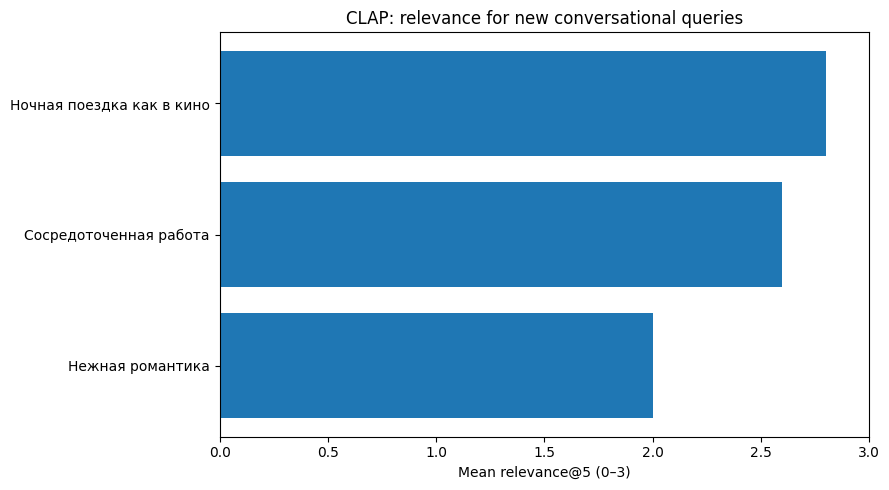


=== ИСХОДНЫЕ ОЦЕНКИ ===


,rank,song_id,similarity,artist,title,query,preview_url,evaluation_id,relevance_0_3
10,1,65,0.451092,Bicep,Lemonder,Нежная романтика,https://audio-ssl.itunes.apple.com/itunes-asse...,11,1
11,2,44,0.443122,Billie Eilish,BIRDS OF A FEATHER,Нежная романтика,https://audio-ssl.itunes.apple.com/itunes-asse...,12,3
12,3,73,0.438322,Cleo Sol,Gentlewoman,Нежная романтика,https://audio-ssl.itunes.apple.com/itunes-asse...,13,3
13,4,61,0.424961,The Marías,Nobody New,Нежная романтика,https://audio-ssl.itunes.apple.com/itunes-asse...,14,3
14,5,38,0.417212,Татьяна Куртукова,Матушка,Нежная романтика,https://audio-ssl.itunes.apple.com/itunes-asse...,15,0
0,1,59,0.512738,beabadoobee,All I Did Was Dream of You (feat. The Marías),Ночная поездка как в кино,https://audio-ssl.itunes.apple.com/itunes-asse...,1,3
1,2,65,0.487441,Bicep,Lemonder,Ночная поездка как в кино,https://audio-ssl.itunes.apple.com/itunes-asse...,2,2
2,3,44,0.480558,Billie Eilish,BIRDS OF A FEATHER,Ночная поездка как в кино,https://audio-ssl.itunes.apple.com/itunes-asse...,3,3
3,4,60,0.466616,The Marías,Back To Me,Ночная поездка как в кино,https://audio-ssl.itunes.apple.com/itunes-asse...,4,3
4,5,73,0.451660,Cleo Sol,Gentlewoman,Ночная поездка как в кино,https://audio-ssl.itunes.apple.com/itunes-asse...,5,3


In [ ]:
# FINAL_NOTEBOOK_NEW_QUERIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

new_ratings = pd.read_csv(
    project_dir / "new_queries_manual_evaluation.csv"
)

new_metrics_saved = pd.read_csv(
    project_dir / "new_queries_metrics.csv"
)

print("=== СТРУКТУРА ОЦЕНОК ===")
print("Столбцы:", new_ratings.columns.tolist())
print("Количество оценок:", len(new_ratings))

required = {
    "query", "rank", "song_id", "relevance_0_3"
}
assert required.issubset(new_ratings.columns)
assert len(new_ratings) == 15
assert new_ratings["query"].nunique() == 3

new_ratings["relevance_0_3"] = pd.to_numeric(
    new_ratings["relevance_0_3"]
)

assert new_ratings["relevance_0_3"].between(0, 3).all()
assert (
    new_ratings.groupby("query").size() == 5
).all()

# Самостоятельно пересчитываем среднюю релевантность
new_metrics = (
    new_ratings.groupby("query", as_index=False)
    .agg(
        mean_relevance_at_5=("relevance_0_3", "mean"),
        excellent_recommendations=(
            "relevance_0_3",
            lambda x: int((x == 3).sum())
        ),
        weak_recommendations=(
            "relevance_0_3",
            lambda x: int((x <= 1).sum())
        )
    )
)

print("\n=== РЕЗУЛЬТАТЫ НОВЫХ ЗАПРОСОВ ===")
display(new_metrics.round(3))

print("\n=== ОБЩИЕ ПОКАЗАТЕЛИ ===")
print(
    "Средняя релевантность:",
    round(new_ratings["relevance_0_3"].mean(), 3)
)
print(
    "Доля оценок 3:",
    f'{(new_ratings["relevance_0_3"] == 3).mean():.1%}'
)
print(
    "Доля оценок 0–1:",
    f'{(new_ratings["relevance_0_3"] <= 1).mean():.1%}'
)

# Визуализация
plot_data = new_metrics.sort_values(
    "mean_relevance_at_5"
)

plt.figure(figsize=(9, 5))
plt.barh(
    plot_data["query"],
    plot_data["mean_relevance_at_5"]
)
plt.xlim(0, 3)
plt.xlabel("Mean relevance@5 (0–3)")
plt.title("CLAP: relevance for new conversational queries")
plt.tight_layout()
plt.show()

print("\n=== ИСХОДНЫЕ ОЦЕНКИ ===")
display(
    new_ratings.sort_values(["query", "rank"])
    .head(15)
)


### Интерпретация результатов

На новых запросах CLAP показал следующую среднюю
релевантность топ-5:

- **Ночная поездка как в кино:** 2,8.
- **Сосредоточенная работа:** 2,6.
- **Нежная романтика:** 2,0.

Средняя релевантность по 15 рекомендациям составила
приблизительно **2,47 из 3**.

При этом **73,3%** рекомендаций получили максимальную
оценку 3, а **20%** — низкую оценку 0 или 1.

Таким образом, модель способна подбирать музыку
для запросов, которые не были предусмотрены ручными
правилами базового алгоритма. Однако отдельные
нерелевантные рекомендации сохраняются, особенно
в сценарии «Нежная романтика».

Это не доказывает, что CLAP лучше базового метода
на новых запросах: прямое сравнительное тестирование
для этих трёх сценариев не проводилось.


## 9. Визуализация эмбеддингов

*PCA-проекция аудиоэмбеддингов и анализ жанровой структуры.*


### Зачем нужна PCA-визуализация

Каждый аудиофрагмент представлен 512-мерным вектором CLAP.
Для визуального анализа используется **метод главных
компонент (PCA)**, который проецирует эмбеддинги
на две оси с максимальной объяснённой дисперсией.

На графике каждая точка соответствует композиции,
а цвет обозначает её жанровую группу.

**Важно:** PCA — инструмент исследовательской
визуализации, а не самостоятельная метрика качества
рекомендаций. Две главные компоненты сохраняют
лишь часть информации исходных векторов.


=== ОБЪЯСНЁННАЯ ДИСПЕРСИЯ ===
PC1: 17.65%
PC2: 13.78%
Суммарно: 31.43%


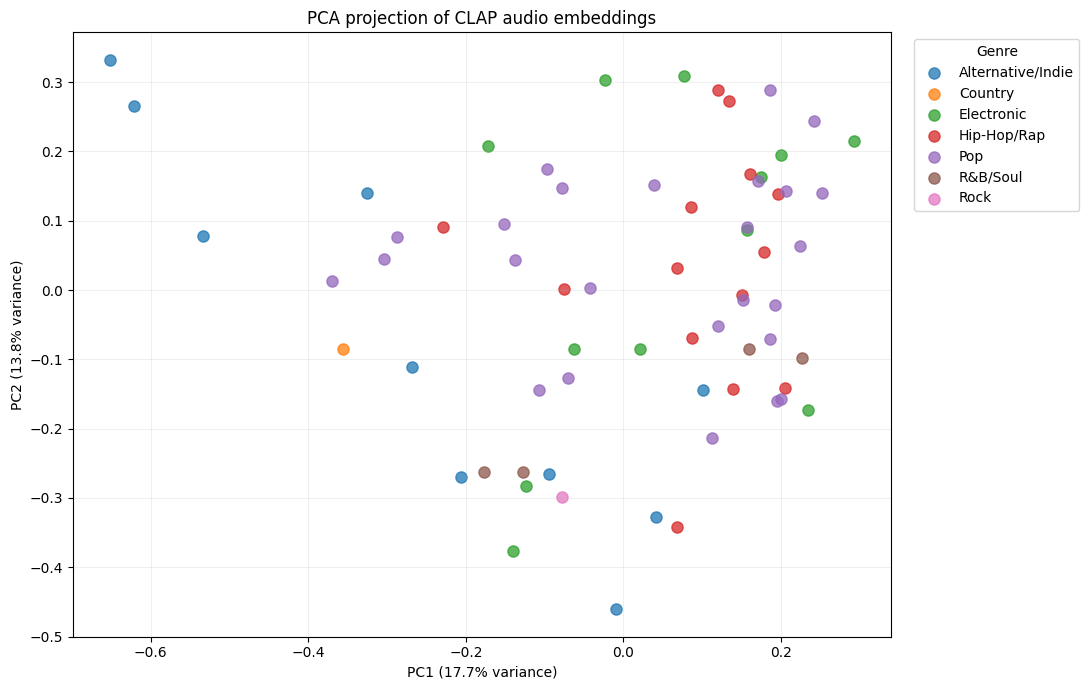


=== ПРИМЕР КООРДИНАТ ===


,song_id,PC1,PC2,artist,title,genre_group
0,2,0.150,-0.008,"Дора, Toxi$",ЗНАК,Hip-Hop/Rap
1,3,0.157,0.090,"Koss, ПЛУТТО",Земляк,Pop
2,5,0.120,-0.052,"By Индия, MOT, Xcho",Шадэ,Pop
3,6,0.086,0.119,"урал гайсин, снялцепи",ты в моих мыслях навсегда,Hip-Hop/Rap
4,7,0.186,-0.071,MIA BOYKA,ЭКСПОНАТ,Pop
5,8,0.252,0.139,ENZRO,Ты не бойся ночи,Pop
6,9,0.206,0.142,"Милана Некрасова, ЦУЕФА, LIZOGUB, Давид Туров,...",Я ТЕБЯ МОГНУ,Pop
7,12,0.224,0.064,Artik & Asti,Лампочки,Pop
8,13,0.112,-0.213,Zivert,GAZ,Pop
9,14,-0.097,0.174,BEARWOLF,Феникс,Pop


In [ ]:
# FINAL_NOTEBOOK_PCA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from IPython.display import display

# Используем те же нормализованные эмбеддинги CLAP
pca = PCA(n_components=2)

coordinates = pca.fit_transform(
    normalized_audio_embeddings
)

pca_df = pd.DataFrame({
    "song_id": song_ids.astype(str),
    "PC1": coordinates[:, 0],
    "PC2": coordinates[:, 1]
})

genre_lookup = dataset[
    ["song_id", "artist", "title", "genre_group"]
].copy()

genre_lookup["song_id"] = (
    genre_lookup["song_id"].astype(str)
)

pca_df = pca_df.merge(
    genre_lookup,
    on="song_id",
    how="left",
    validate="one_to_one"
)

pca_df["genre_group"] = (
    pca_df["genre_group"].fillna("Unknown")
)

explained = pca.explained_variance_ratio_

print("=== ОБЪЯСНЁННАЯ ДИСПЕРСИЯ ===")
print(f"PC1: {explained[0]:.2%}")
print(f"PC2: {explained[1]:.2%}")
print(f"Суммарно: {explained.sum():.2%}")

plt.figure(figsize=(11, 7))

for genre, group in pca_df.groupby("genre_group"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=genre,
        alpha=0.75,
        s=65
    )

plt.xlabel(f"PC1 ({explained[0]:.1%} variance)")
plt.ylabel(f"PC2 ({explained[1]:.1%} variance)")
plt.title("PCA projection of CLAP audio embeddings")
plt.legend(
    title="Genre",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("\n=== ПРИМЕР КООРДИНАТ ===")
display(pca_df.head(10).round(3))


### Интерпретация PCA

В ранее проведённом анализе первые две компоненты
объясняли около **31,4%** дисперсии эмбеддингов.

На двумерной проекции жанровые группы частично
перекрываются. Это означает, что представления CLAP
не разделяют музыкальный каталог на полностью
обособленные жанровые кластеры в пространстве
первых двух компонент.

При этом нельзя заключать, что модель не различает
жанры вообще: большая часть информации остаётся
за пределами двумерной проекции.

Наблюдение согласуется с задачей исследования:
для рекомендаций по пользовательскому намерению
важно учитывать не только жанр, но и особенности
звучания, атмосферу и контекст прослушивания.


## 10. Демонстрация рекомендательной системы

*Интерактивный поиск композиций по текстовому запросу.*


### Демонстрация рекомендаций по текстовому запросу

Ниже реализована простая рекомендательная система
на основе предобученной модели **LAION-CLAP**.

Пользователь описывает желаемую музыку текстом.
Система преобразует запрос в 512-мерный текстовый
эмбеддинг, сравнивает его с сохранёнными аудиоэмбеддингами
и возвращает пять композиций с наибольшим косинусным
сходством.

**Важно:**

- В демонстрации рекомендуется вводить запросы на английском.
- При первом запуске может потребоваться скачать модель.
- Повторно скачивать и обрабатывать аудиопревью не нужно.
- Результаты ограничены 67 композициями с аудиоэмбеддингами.
- Косинусное сходство не является вероятностью релевантности.


In [12]:
# FINAL_NOTEBOOK_DEMO

import sys
import subprocess
import importlib.util

# Устанавливаем Transformers только при необходимости
if importlib.util.find_spec("transformers") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "transformers==4.46.3", "-q"
    ])

import numpy as np
import pandas as pd
import torch
from transformers import ClapModel, ClapProcessor
from IPython.display import display

MODEL_NAME = "laion/clap-htsat-unfused"

device = (
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Устройство:", device)
print("Загружаем текстовый энкодер CLAP...")

clap_processor = ClapProcessor.from_pretrained(
    MODEL_NAME
)

clap_model = ClapModel.from_pretrained(
    MODEL_NAME
).to(device)

clap_model.eval()

# Подготавливаем каталог
demo_catalog = (
    pd.DataFrame({
        "song_id": song_ids.astype(str)
    })
    .merge(
        dataset[
            [
                "song_id",
                "artist",
                "title",
                "genre_group",
                "preview_url"
            ]
        ],
        on="song_id",
        how="left",
        validate="one_to_one"
    )
)

demo_audio_vectors = (
    audio_embeddings
    / np.linalg.norm(
        audio_embeddings, axis=1, keepdims=True
    )
)

def recommend_music(query, top_k=5):
    """
    Рекомендует музыку по англоязычному описанию.
    Возвращает таблицу из top_k композиций.
    """
    if not isinstance(query, str) or not query.strip():
        raise ValueError("Введите непустой текстовый запрос")

    inputs = clap_processor(
        text=[query],
        return_tensors="pt",
        padding=True
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        text_output = clap_model.get_text_features(
            **inputs
        )

    # Совместимость с версиями Transformers,
    # возвращающими объект с pooler_output
    if hasattr(text_output, "pooler_output"):
        text_vector = text_output.pooler_output
    else:
        text_vector = text_output

    text_vector = (
        text_vector.detach()
        .cpu()
        .numpy()
        .reshape(-1)
    )

    text_vector = (
        text_vector / np.linalg.norm(text_vector)
    )

    similarities = demo_audio_vectors @ text_vector

    top_indices = np.argsort(
        similarities
    )[::-1][:top_k]

    result = demo_catalog.iloc[
        top_indices
    ].copy()

    result.insert(
        0,
        "rank",
        range(1, len(result) + 1)
    )

    result["similarity"] = (
        similarities[top_indices]
    )

    return result[
        [
            "rank",
            "artist",
            "title",
            "genre_group",
            "similarity",
            "preview_url"
        ]
    ].reset_index(drop=True)

# Пример запроса
user_query = (
    "Calm, melancholic and atmospheric music "
    "for an evening walk"
)

print("\nВаш запрос:", user_query)
display(
    recommend_music(user_query, top_k=5).round(3)
)


Устройство: cpu
Загружаем текстовый энкодер CLAP...


preprocessor_config.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.39k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  614MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/447 [00:00<?, ?it/s]


Ваш запрос: Calm, melancholic and atmospheric music for an evening walk


,rank,artist,title,genre_group,similarity,preview_url
0,1,Bicep,Lemonder,Electronic,0.401,https://audio-ssl.itunes.apple.com/itunes-asse...
1,2,Overmono,After The Rain,Electronic,0.389,https://audio-ssl.itunes.apple.com/itunes-asse...
2,3,Sabrina Carpenter,Manchild,Pop,0.375,https://audio-ssl.itunes.apple.com/itunes-asse...
3,4,beabadoobee,Beaches,Alternative/Indie,0.374,https://audio-ssl.itunes.apple.com/itunes-asse...
4,5,The Marías,Back To Me,Alternative/Indie,0.370,https://audio-ssl.itunes.apple.com/itunes-asse...


## 11. Выводы и ограничения

*Итоговая интерпретация экспериментов,
методологические ограничения и направления развития.*


<!-- FINAL_NOTEBOOK_CONCLUSIONS -->

### Основные результаты

В работе исследована возможность подбирать музыкальные
композиции по текстовому описанию пользовательского
намерения: настроения, ситуации или желаемого звучания.

**1. Подготовлен музыкальный каталог.**

Сформирован набор из 80 композиций с метаданными.
Для 67 треков были доступны короткие аудиопревью,
по которым рассчитаны акустические признаки
и 512-мерные эмбеддинги CLAP.

**2. Исследованы музыкальные признаки.**

Рассчитаны темп (BPM) и характеристики акустической
энергии. Они позволяют описывать отдельные аспекты
звучания, но не заменяют оценку настроения
и пользовательской релевантности.

**3. Реализовано три подхода к рекомендациям.**

- A — косинусное сходство текста и аудио в CLAP.
- B — экспериментальное центрирование эмбеддингов.
- C — базовый алгоритм на основе жанра и BPM.

**4. Проведено сравнение на пяти сценариях.**

| Метод | Mean Relevance@5 | NDCG@5 |
|---|---:|---:|
| A — CLAP | 2,44 | 0,666 |
| B — Centered CLAP | 2,16 | 0,592 |
| C — Жанр + BPM | 2,80 | 0,907 |

В рамках выбранных сценариев наилучшие показатели
получил метод C. Однако его правила были заранее
настроены под эти же запросы, поэтому результат
не свидетельствует о превосходстве базового
алгоритма на произвольных формулировках.

Центрирование CLAP-эмбеддингов в проведённом
эксперименте не улучшило качество рекомендаций.

**5. CLAP проверен на новых запросах.**

Для трёх дополнительных сценариев получена
средняя релевантность 2,47 из 3. Лучший результат
наблюдался для запроса «Ночная поездка как в кино»
(2,8), а наиболее сложным оказался запрос
«Нежная романтика» (2,0).

Эти результаты показывают применимость CLAP
к свободным текстовым описаниям, но не доказывают
его преимущество перед другими методами.

**6. Изучена структура аудиоэмбеддингов.**

Первые две главные компоненты PCA объяснили
31,43% дисперсии. На двумерной проекции
жанровые группы частично перекрываются.

**7. Создан работающий прототип.**

Реализована функция, которая преобразует
англоязычный текстовый запрос в эмбеддинг CLAP,
сравнивает его с аудиоэмбеддингами и возвращает
пять наиболее близких композиций.

### Ограничения исследования

1. Небольшой и неравномерный каталог: 80 композиций,
   аудиоэмбеддинги доступны только для 67.
2. Используются короткие аудиопревью, а не полные записи.
3. Оценки релевантности получены от одного слушателя.
4. Основной эксперимент включает всего пять запросов,
   дополнительный — три.
5. Правила базового алгоритма настроены под исходные
   пять сценариев.
6. Для CLAP использовались английские формулировки,
   подготовленные вручную.
7. Не проводились статистические тесты значимости.
8. NDCG@5 рассчитан относительно общего пула
   оценённых кандидатов, а не полного каталога.
9. Косинусное сходство CLAP не является вероятностью
   того, что композиция понравится пользователю.

### Возможные направления развития

- Расширить и сбалансировать музыкальный каталог.
- Привлечь нескольких независимых оценщиков.
- Проверить качество на большем числе новых запросов.
- Добавить поддержку русскоязычных запросов.
- Исследовать гибридную модель, объединяющую CLAP,
  жанр и акустические характеристики.
- Провести пользовательское тестирование
  и оценить разнообразие рекомендаций.

### Итог

**CLAP позволяет реализовать рекомендации музыки
по свободному текстовому описанию пользовательского
намерения без предварительного задания правил
для каждого сценария.**

В то же время простой интерпретируемый алгоритм
на основе жанра и BPM может быть эффективнее
на заранее известных запросах.

Поэтому перспективным направлением представляется
гибридный подход, сочетающий гибкость семантических
эмбеддингов и управляемость музыкальных признаков.
